# Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lr1_helpers as h
from time import perf_counter
from datetime import datetime

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

import importlib
importlib.reload(h)
curr_time = datetime.now()
print(f"Модули обновлены.\nВремя: {curr_time.strftime('%Y-%m-%d %H:%M:%S')}")

Модули обновлены.
Время: 2026-09-26 09:20:13


In [216]:
def graph_setup():
    sns.set_style("whitegrid")
    sns.set_context("notebook", font_scale=1.2)
    plt.rcParams['figure.figsize'] = [10, 8]
    plt.rcParams['figure.dpi'] = 100

graph_setup()

# Лабораторная работа №1

In [260]:
data = np.loadtxt("lab1data.txt", delimiter=",")
train_data, test_data = h.train_test(data, test_size=0.3)
X_train, y_train = train_data[:, 0], train_data[:, 1]
X_test, y_test = test_data[:, 0], test_data[:, 1] 
X_train = X_train.reshape(-1, 1)
X_test = X_test.reshape(-1, 1)

In [261]:
%%time
custom_model = h.CustomLinearRegression()
custom_model.fit(X_train, y_train, compute_cost=True, method="vector", epochs=50000)
theta = custom_model.theta
y_pred = custom_model.predict(X_test)
print(f"R2 score: {h.r2_score(y_test, y_pred):.4f}")
print(theta)

R2 score: 0.8870
[-3.16158446  1.12873903]
CPU times: total: 875 ms
Wall time: 882 ms


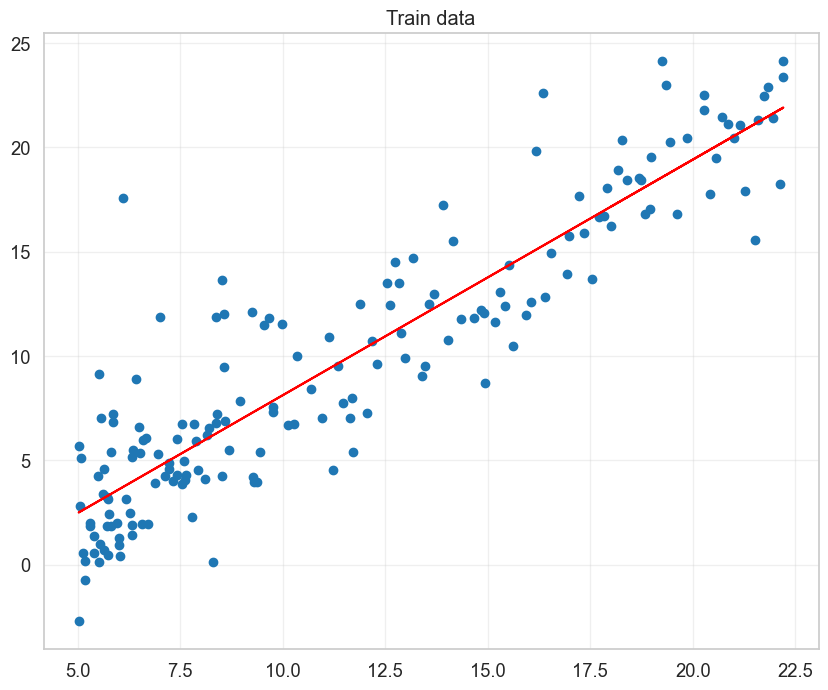

In [232]:
h.plotData(X_train, y_train, [theta], legend=False, title="Train data")

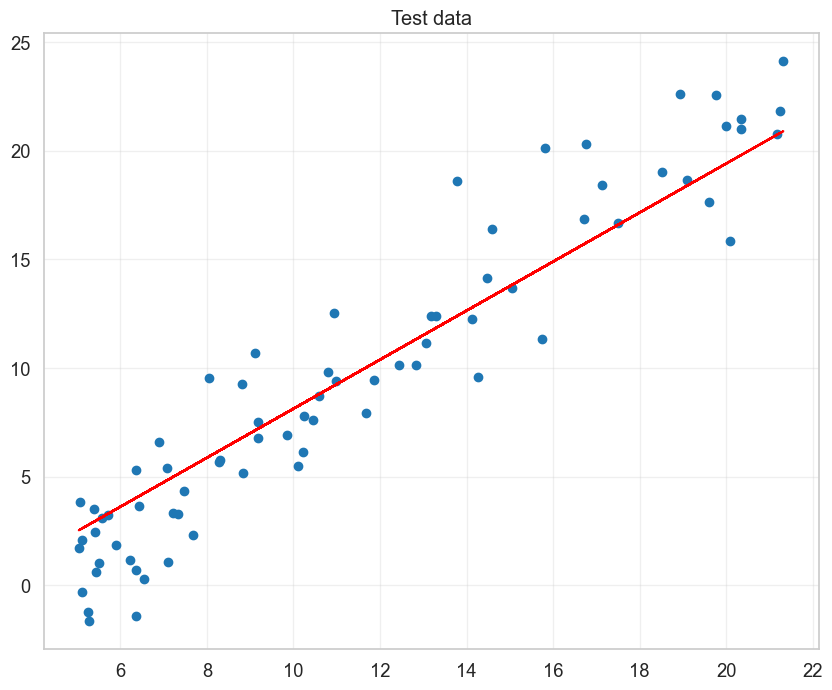

In [233]:
h.plotData(X_test, y_test, [theta], legend=False, title="Test data")

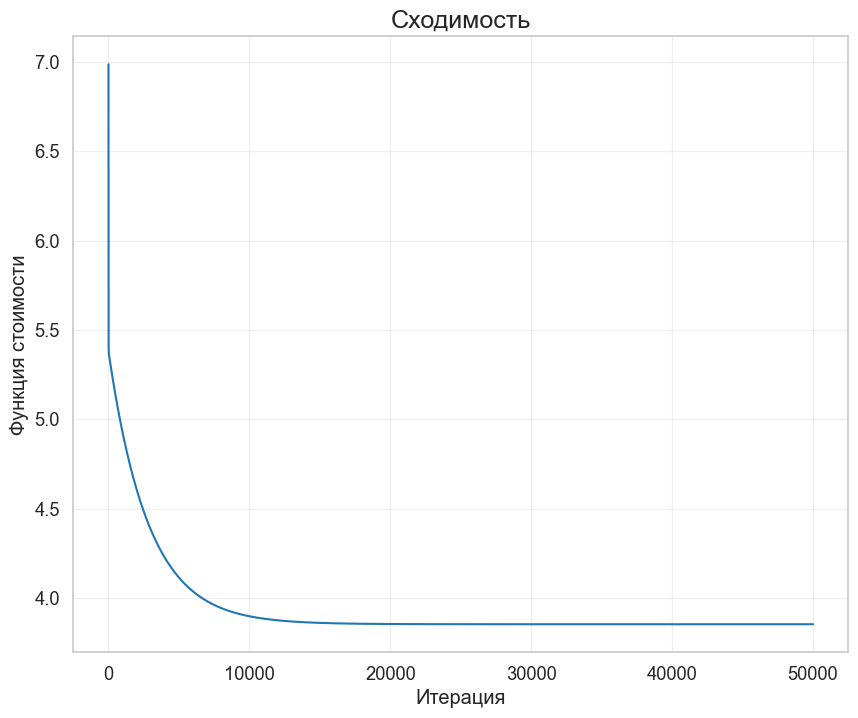

In [235]:
iterations, costs = zip(*custom_model.cost)
h.plotCost(iterations, costs)

In [269]:
%%time

rows = []

for method in ["vector", "loop", "manual"]:
    epochs = 50000
    custom_model = h.CustomLinearRegression()
    
    start_time = perf_counter()
    custom_model.fit(X_train, y_train, compute_cost=False, method=method, epochs=epochs)
    end_time = perf_counter() - start_time
    
    theta = custom_model.theta
    y_pred = custom_model.predict(X_test)
    r2 = h.r2_score(y_test, y_pred)
    row = {"model": f"CustomLinearRegression_{method}", "time": f"{end_time:.4f}", "epochs": epochs, "r2_score": f"{r2:.4f}"}
    rows.append(row)


start_time = perf_counter()
sk_model = LinearRegression()
sk_model.fit(X_train, y_train)
end_time = perf_counter() - start_time
y_pred = sk_model.predict(X_test)
r2 = h.r2_score(y_test, y_pred)

row = {"model": f"SklearnLinearRegression", "time": f"{end_time:.4f}", "epochs": 1, "r2_score": f"{r2:.4f}"}
rows.append(row)

results = pd.DataFrame(rows)

CPU times: total: 39.7 s
Wall time: 39.8 s


In [270]:
results

,model,time,epochs,r2_score
0,CustomLinearRegression_vector,0.4756,50000,0.8870
1,CustomLinearRegression_loop,1.6238,50000,0.8870
2,CustomLinearRegression_manual,37.6539,50000,0.8870
3,SklearnLinearRegression,0.0010,1,0.8870
